In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
url= 'https://raw.githubusercontent.com/NUELBUNDI/Machine-Learning-Data-Set/refs/heads/main/Score%20Form%20%20Responses.csv'

df = pd.read_csv(url)

#### Analysis the Performance of the Class?

1. Data Cleaning

In [3]:
df.head()

,Timestamp,Which Room were you in?,Which group are you grading,Give a score out of 5
0,03-10-26 18:09,Room 2,Room 1,4
1,03-10-26 18:09,Room 5,Room 1,5
2,03-10-26 18:09,Room 4,Room 1,5
3,03-10-26 18:09,Room 6,Room 1,5
4,03-10-26 18:09,Room 9,Room 1,4


In [4]:
df['Which Room were you in?'].unique()

<StringArray>
[   'Room 2',    'Room 5',    'Room 4',    'Room 6',    'Room 9',    'Room 3',
    'Room 8',    'Room 7',    'Room 1', 'Main Room']
Length: 10, dtype: str

In [5]:
# I want to rename rooms with specific name

map_dict = {
        "Room 1":"Synergy group",
        "Room 2":"StatSquad",
        "Room 3":"Tana",
        "Room 4":"marvels",
        "Room 5":"Visualizers",
        "Room 6":"Data Architects",
        "Room 7":"Sonic",##### Bravo
        "Room 8":"dataviz",
        "Room 9":"brainy badgers",
        "Main Room":"Tajiri",
    }

# This is a map dictionary

In [6]:
df.rename(columns={
    "Which Room were you in?" :"grader_room",
    'Which group are you grading':"graded_group",
    'Give a score out of 5':'score'

},inplace=True)

In [7]:
df['grader_room_mapped']   = df['grader_room'].map(map_dict) #
df['graded_group_mapped']  = df['graded_group'].map(map_dict) #

In [8]:
df.drop(columns=['grader_room','graded_group'],inplace=True)

In [15]:
# Data Engineering .Creating new features in data

df['Timestamp'] = pd.to_datetime(df['Timestamp'], format="%d/%m/%y")

df['Time'] = df['Timestamp'].dt.time
df['Date'] = df['Timestamp'].dt.date

2. **Data Analysis**

Approach of doing data analysis

1.  univariate analysis
    
    - Analysis one variable in the dataset
       - Use Stasts  e.g measure of central tendency, e...
       - Use Visualization
       - Hybrid

In [16]:
# What is distribution of score

df['score'].describe()

count    316.000000
mean       3.857595
std        1.174588
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max        5.000000
Name: score, dtype: float64

 Insights

 - Mean is 3.8
 - 75 Percent of score got atleast 5

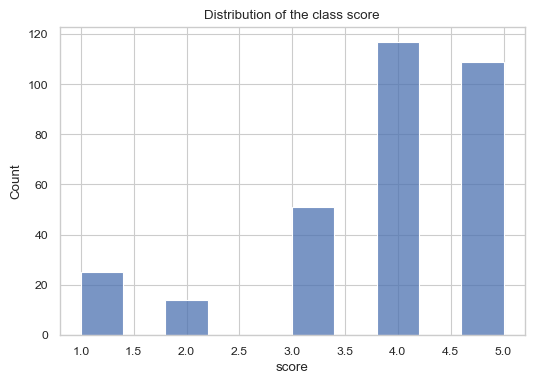

In [17]:
sns.set_theme(
    context='paper',
    style= 'whitegrid'
)
plt.figure(figsize=(6,4))
sns.histplot(data =df,x='score');
plt.title('Distribution of the class score')
plt.show()

In [18]:
# Whic graded_room had a lot graded?

df['graded_group_mapped'].value_counts().sort_values(ascending=False).reset_index()

,graded_group_mapped,count
0,Synergy group,36
1,Tana,36
2,Sonic,36
3,marvels,35
4,StatSquad,34
5,Visualizers,34
6,Data Architects,32
7,dataviz,27
8,brainy badgers,25
9,Tajiri,21


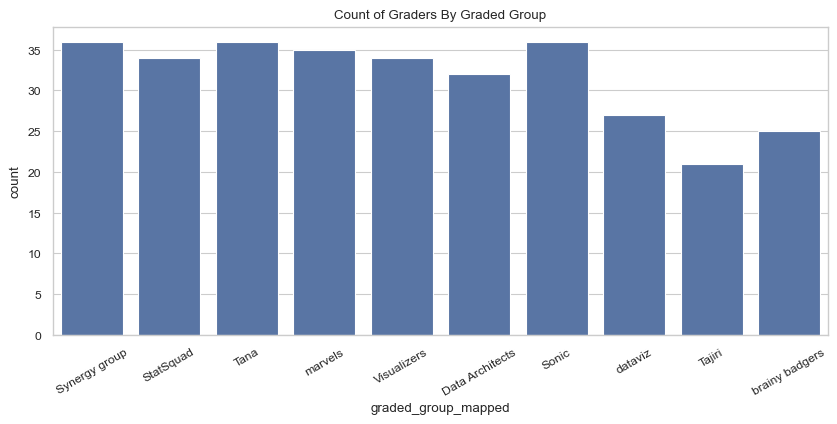

In [19]:
sns.set_theme(
    context='paper',
    style= 'whitegrid'
)
plt.figure(figsize=(10,4))
sns.countplot(data =df,x='graded_group_mapped');
plt.title('Count of Graders By Graded Group')
plt.xticks(rotation=30)
plt.show()

-- Insights

-Tajiri got few grading people at 21

2. Bivariate Analysis

- Analysis with aim of establish a relationship btw 2 variables

In [20]:
# What is the mean score compared to count

df.groupby('graded_group_mapped').agg(

        mean_score          =  ('score','mean'),
        median_score        =  ('score','median'),
        count_of_graders    =  ('grader_room_mapped','size')

).reset_index().sort_values(by='mean_score', ascending=False)

,graded_group_mapped,mean_score,median_score,count_of_graders
1,Sonic,4.527778,5.0,36
3,Synergy group,4.500000,5.0,36
0,Data Architects,4.343750,4.0,32
6,Visualizers,4.323529,4.0,34
9,marvels,4.057143,4.0,35
4,Tajiri,4.047619,4.0,21
8,dataviz,3.962963,4.0,27
2,StatSquad,3.794118,4.0,34
5,Tana,2.861111,3.0,36
7,brainy badgers,1.680000,1.0,25


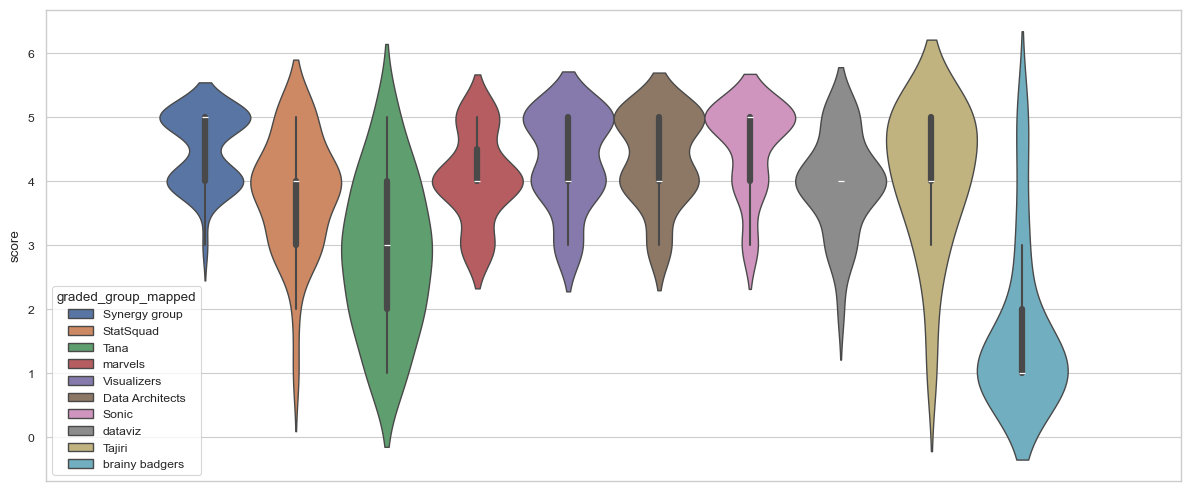

In [21]:
plt.figure(figsize=(12,5))

sns.violinplot(
    data = df,
    y='score',
    hue='graded_group_mapped'
)
plt.tight_layout()
plt.show()